# Passive Fail-Slow Diagnosis in Disaggregated LLM Inference
## Experiment results

Select an experiment directory below, then run all cells. The default opens the executed 96-run simulation. The measured CPU study is in `results/cpu-study`. A completed GPU study has the same output format. The README contains the launcher, telemetry contract and experiment definitions.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

study_dir = Path("results/synthetic")
plan = json.loads((study_dir / "study.json").read_text())
baseline = json.loads((study_dir / "calibration.json").read_text())
trials = pd.DataFrame(plan["trials"])
methods = pd.read_csv(study_dir / "summary.csv").set_index("method")
incidents = pd.read_csv(study_dir / "incidents.csv")
print(f"{plan['backend']} backend | {plan['workers']} workers per stage | {len(trials)} runs | {plan['duration_s']:g} seconds/run")
display(trials.groupby("split").size().rename("runs").to_frame())
print("Frozen model SHA-256", baseline["baseline_sha256"])

sim backend | 2 workers per stage | 96 runs | 180 seconds/run
Frozen model SHA-256 12f420df404f7bac09eeca5e214ae6d73ea66d9e77a0560f961deddfd1be5645


,runs
split,
control,36
fit,4
scale,4
test,48
threshold,4


## Localization, delay and false alarms

First top-1 and top-3 use every injected incident as the denominator. A new diagnostic episode starts when a previously clear window emits a ranking. Delay is conditional on a new episode. Healthy exposure includes workload-only trials and paired no-fault controls.

,incidents,top1,top3,misses,wrong_first,median_new_episode_delay_s,false_episodes,healthy_hours,episodes_per_hour
method,,,,,,,,,
conditioned,36,24,24,12,0,15.0,6,2.0,3.0
historical,36,12,12,24,0,25.0,3,2.0,1.5
work_rate,36,16,16,17,3,25.0,11,2.0,5.5
matched_peer,36,24,24,12,0,25.0,1,2.0,0.5


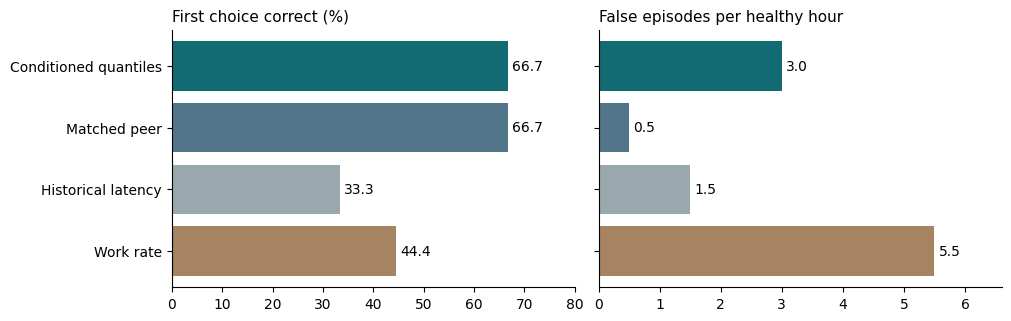

In [2]:
display(methods[["incidents", "top1", "top3", "misses", "wrong_first", "median_new_episode_delay_s",
                 "false_episodes", "healthy_hours", "episodes_per_hour"]].round(3))
names = {"conditioned":"Conditioned quantiles", "matched_peer":"Matched peer",
         "historical":"Historical latency", "work_rate":"Work rate"}
view = methods.loc[list(names)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), layout="constrained")
y = np.arange(len(view))
for ax, col, title in zip(axes, ["top1_fraction", "episodes_per_hour"],
                         ["First choice correct (%)", "False episodes per healthy hour"]):
    values = view[col].values * (100 if col == "top1_fraction" else 1)
    bars = ax.barh(y, values, color=["#126a72", "#537589", "#98a8ad", "#a68361"])
    ax.set_yticks(y, list(names.values()) if ax == axes[0] else [""] * len(y))
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11, loc="left")
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_xlim(0, max(max(values)*1.2, 1))
    ax.spines[["right","top"]].set_visible(False)
plt.show()

## Which faults were identifiable?

Inspect withheld transfer measurements and sparse routing alongside isolated and mixed faults. The table preserves abstentions and incorrect first choices. A severity of 1.5 or 3 is the requested service multiplier.

In [3]:
conditioned = incidents[incidents.method == "conditioned"].copy()
breakdown = conditioned.groupby(["case","strength"]).agg(
    injected=("run_id","size"), correct_first=("top1","sum"),
    any_ranking=("ranked","sum"), unknown_window_fraction=("unknown_fraction","mean"))
display(breakdown.round(2))

injected  ...  unknown_window_fraction
case          strength            ...                         
decode        1.5              3  ...                     0.10
              3.0              3  ...                     0.10
missing_path  1.5              3  ...                     1.00
              3.0              3  ...                     1.00
mixed         1.5              3  ...                     0.10
              3.0              3  ...                     0.10
prefill       1.5              3  ...                     0.10
              3.0              3  ...                     0.10
sparse_worker 1.5              3  ...                     1.00
              3.0              3  ...                     1.00
transfer      1.5              3  ...                     0.23
              3.0              3  ...                     0.13

[12 rows x 4 columns]

## Follow one decode incident

The upper panel shows the component score and calibrated threshold. The lower panel shows the p99 client ITL and the target. SLO decisions in the implementation use violation fractions and minimum sample counts. Shading marks the scheduled intervention.

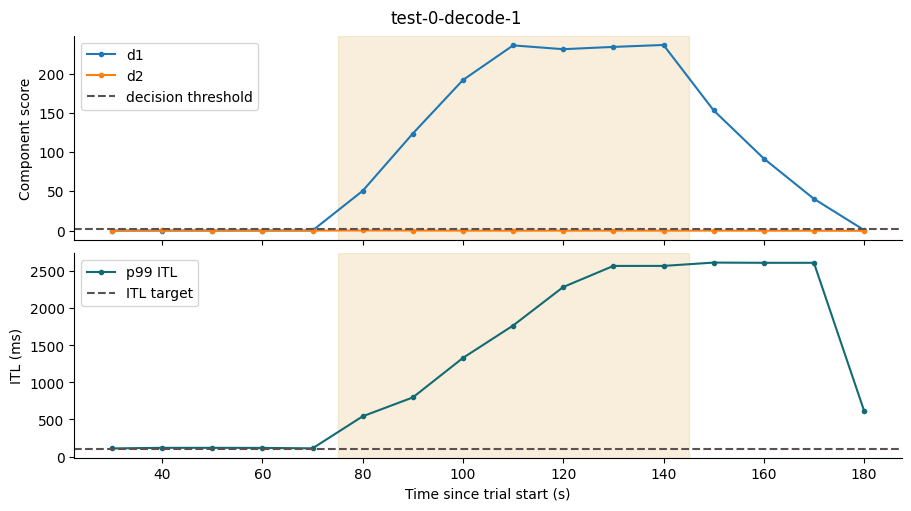

,t_s,ranked,slo_alarm,demand_changed,explanation,unknown_reason
640,30.0,[],True,False,unknown,unresolved_slowdown
644,40.0,[],True,False,unknown,unresolved_slowdown
648,50.0,[],True,False,unknown,unresolved_slowdown
652,60.0,[],True,False,unknown,unresolved_slowdown
656,70.0,[],True,False,unknown,unresolved_slowdown
660,80.0,[],True,False,unknown,unresolved_slowdown
664,90.0,"[""d1""]",True,False,degradation,
668,100.0,"[""d1""]",True,False,degradation,
672,110.0,"[""d1""]",True,False,degradation,
676,120.0,"[""d1""]",True,False,degradation,


In [4]:
rid = conditioned.query("case == 'decode' and strength == 3").iloc[0].run_id
case = trials.set_index("rid").loc[rid]
scores = pd.read_csv(study_dir / "component_scores.csv.gz")
scores = scores[(scores.run_id == rid) & (scores.method == "conditioned")]
dec = pd.read_csv(study_dir / "decisions.csv.gz")
dec = dec[(dec.run_id == rid) & (dec.method == "conditioned")]
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
for c in baseline["components"]["decode"]:
    g = scores[scores.component == c]
    axes[0].plot(g.t_s, g.score, marker=".", label=c)
axes[0].axhline(baseline["thresholds"]["conditioned"], ls="--", color="#5c5050", label="decision threshold")
axes[0].set_ylabel("Component score")
axes[1].plot(dec.t_s, dec.itl_ms_p99, marker=".", color="#126a72", label="p99 ITL")
axes[1].axhline(plan["settings"]["itl_slo_ms"], ls="--", color="#5c5050", label="ITL target")
axes[1].set(xlabel="Time since trial start (s)", ylabel="ITL (ms)")
for ax in axes:
    ax.axvspan(case.onset, case.end, color="#e4be72", alpha=.25)
    ax.legend(loc="upper left")
    ax.spines[["right","top"]].set_visible(False)
fig.suptitle(rid)
plt.show()
display(dec[["t_s","ranked","slo_alarm","demand_changed","explanation","unknown_reason"]].fillna(""))

## Paired service impact

Deltas subtract the matched healthy control's whole-run measurement. Cache and queue effects can produce a service anomaly with little visible impact on the aggregate user-facing metrics.

In [5]:
pairs = pd.read_csv(study_dir / "paired_impact.csv").merge(
    trials[["rid","case"]], left_on="run_id", right_on="rid", validate="one_to_one")
display(pairs.groupby(["case","strength"])[["ttft_p99_ms_delta","itl_p99_ms_delta","completed_rps_delta"]]
        .median().round(2))
display(methods[["explanation_windows","explanation_accuracy","explanation_coverage"]].round(3))

ttft_p99_ms_delta  ...  completed_rps_delta
case          strength                     ...                     
decode        1.5                   41.88  ...                  0.0
              3.0                 3056.76  ...                  0.0
missing_path  1.5                    0.00  ...                  0.0
              3.0                   22.01  ...                  0.0
mixed         1.5                  316.59  ...                  0.0
              3.0                 3602.62  ...                  0.0
prefill       1.5                   38.68  ...                  0.0
              3.0                  184.87  ...                  0.0
sparse_worker 1.5                    0.00  ...                  0.0
              3.0                    0.00  ...                  0.0
transfer      1.5                    0.00  ...                  0.0
              3.0                    0.00  ...                  0.0

[12 rows x 3 columns]

,explanation_windows,explanation_accuracy,explanation_coverage
method,,,
conditioned,217,0.654,0.682
historical,217,0.475,0.475
work_rate,217,0.571,0.571
matched_peer,217,0.682,0.682


## Execution evidence

The CPU pilot checks cached versus unsplit token IDs. The overhead trials alternate the order of paired runs. For a GPU experiment, these cells read its own pilot and overhead results when present. GPU timings become available after running the suite on a CUDA host.

In [6]:
pilot_dir = Path("results/cpu-study") if plan["backend"] == "sim" else study_dir
pilot = json.loads((pilot_dir / "pilot.json").read_text())
print("Pilot engine", next(iter(pilot["profile"]["workers"].values()))["engine"])
display(pd.DataFrame(pilot["paths"])[["prefill","decode","bytes","loaded_tokens","exact_match"]])
overhead = study_dir / "overhead" / "overhead_paired.csv"
if study_dir in (Path("results/synthetic"), Path("results/cpu-study")):
    overhead = Path("results/cpu-overhead/overhead_paired.csv")
if overhead.exists():
    display(pd.read_csv(overhead).round(2))
else:
    print("This study has no paired overhead measurements in its output directory.")

Pilot engine numpy-causal-attention


,prefill,decode,bytes,loaded_tokens,exact_match
0,p1,d1,33514,129,True
1,p1,d2,33514,129,True
2,p2,d1,33514,129,True
3,p2,d2,33514,129,True


,rep,completed_rps_change_pct,ttft_p99_ms_change_pct,itl_p99_ms_change_pct
0,0,0.22,-5.41,-11.45
1,1,0.00,-48.99,18.21
2,2,0.00,-7.54,-11.22


## Measured Qwen inference on vLLM

The following measurements come from a separate single-engine CPU run of Qwen2.5-0.5B-Instruct. The first-ranked component and false episodes are evaluated against matched interventions and controls. Transfer diagnosis requires the separate-worker SageMaker study.

In [7]:
from pathlib import Path
import json
import pandas as pd

qwen_dir = Path("results/qwen-vllm-cpu")
study = json.loads((qwen_dir / "study.json").read_text())
runs = [json.loads(path.read_text()) for path in sorted((qwen_dir / "runs").glob("*/complete.json"))]
print(study["model"], "| vLLM", study["vllm"], "|", study["device"])
print(sum(r["requests"] for r in runs), "requests and", sum(r["forward_records"] for r in runs), "measured model forwards")
print(pd.read_csv(qwen_dir / "summary.csv").fillna("").to_string(index=False))
print()
for sample in json.loads((qwen_dir / "examples.json").read_text()):
    print("Q.", sample["prompt"])
    print("A.", sample["output"])

Qwen/Qwen2.5-0.5B-Instruct | vLLM 0.17.0 | CPU
240 requests and 934 measured model forwards
         run_id target first_ranking ranking_before_onset first_correct_delay_s false_episodes  requests
prefill-control               ["d1"]                   []                                  1.0        32
  prefill-fault     p1        ["p1"]               ["p1"]              2.638669                       32
   decode-fault     d1        ["p1"]                   []              2.136819                       32
 decode-control               ["d1"]               ["d1"]                                  1.0        32

Q. What is the capital of France? Answer in one short sentence.
A. The capital of France is Paris.
Q. What is 7 times 8? Answer with the number.
A. 7 times 8 is 56.
